# Single-scan PET displacement: models, simulation and study design

This notebook walks through the `petdisp` package, which implements the kinetic models of
Laurell et al., *Kinetic models for estimating occupancy from single-scan PET displacement studies*,
JCBFM 2023;43(9):1544-56, plus a time-varying SRTM whose occupancy is driven by the displacing
drug's brain concentration profile.

1. Define a tracer (Kd, fND), regions (Bmax), an endogenous competitor and a displacing drug (brain PK, Ki).
2. Simulate one noisy displacement scan.
3. Fit the models and report baseline BPND, displacement occupancy, apparent EC50 and the endogenous competitor level.
4. Compare with the paper's plasma-input 1TC model and with a two-scan Lassen plot.
5. Map how drug dose and injection time change the reliability of each estimate, and pick a design.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import petdisp as pd

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "lines.linewidth": 2,
                     "figure.dpi": 110})
rng = np.random.default_rng(1)

## 1. Scenario

`example_scenario()` gives a [11C]UCB-J-like tracer (VND = 4 mL/cm³, baseline BPND 1.5 to 4.6) with four
target regions and a reference region, a Feng plasma input, a 150-min scan, and a drug given at 60 min.

Receptor-level parameters: tracer Kd = 3 nM, fND = 0.3, and an endogenous competitor with
E/K_E = 0.5 (it occupies a third of the receptors at baseline). Each region's Bmax is set so the baseline BPND,
*with* the endogenous competitor present, has the listed value.

The drug's free brain concentration follows `DrugPK` (IV bolus, bi-exponential plasma disposition,
brain equilibration rate `keq`). Replace it with `TabulatedProfile(t_rel, conc, ref_dose)` to use a
measured or externally simulated brain profile.

In [2]:
sc = pd.example_scenario()
sc.drug.dose, sc.drug.t_inj, sc.drug.ki = 10.0, 60.0, 0.05   # mg, min, ug/mL (free brain)
print("tracer:", sc.tracer)
print("drug PK:", sc.drug.pk)
print("apparent EC50 = Ki (1 + E/K_E) =", sc.ec50_app)
for r in sc.regions:
    print(f"{r.name:12s} K1={r.K1:.2f} VND={r.VND:.1f} Bmax={r.bmax:6.1f} nM  BPND0={sc.bp0(r):.2f}")

tracer: Tracer(kd=3.0, fnd=0.3, half_life=20.364, molar_activity=None)
drug PK: DrugPK(V=50.0, k1=0.1, k2=0.005, f1=0.5, keq=0.3, Kp_uu=1.0, fu=1.0, infusion_min=0.3333333333333333)
apparent EC50 = Ki (1 + E/K_E) = 0.07500000000000001
putamen      K1=0.30 VND=4.0 Bmax=  69.0 nM  BPND0=4.60
frontal      K1=0.32 VND=4.0 Bmax=  52.5 nM  BPND0=3.50
thalamus     K1=0.35 VND=4.0 Bmax=  39.0 nM  BPND0=2.60
hippocampus  K1=0.25 VND=4.0 Bmax=  22.5 nM  BPND0=1.50


## 2. Simulate one displacement scan

{'bp0': array([4.6, 3.5, 2.6, 1.5]), 'VT': array([22.4, 18. , 14.4, 10. ]), 'VND': array([4., 4., 4., 4.]), 'ec50_app': 0.07500000000000001, 'endo_ratio': 0.5, 'endo_conc': None, 'occ_peak': 0.6548807030367914, 'occ_end': 0.4639664637889087, 'drug_peak_conc': 0.1423161589628394, 't_peak_conc': 67.9}


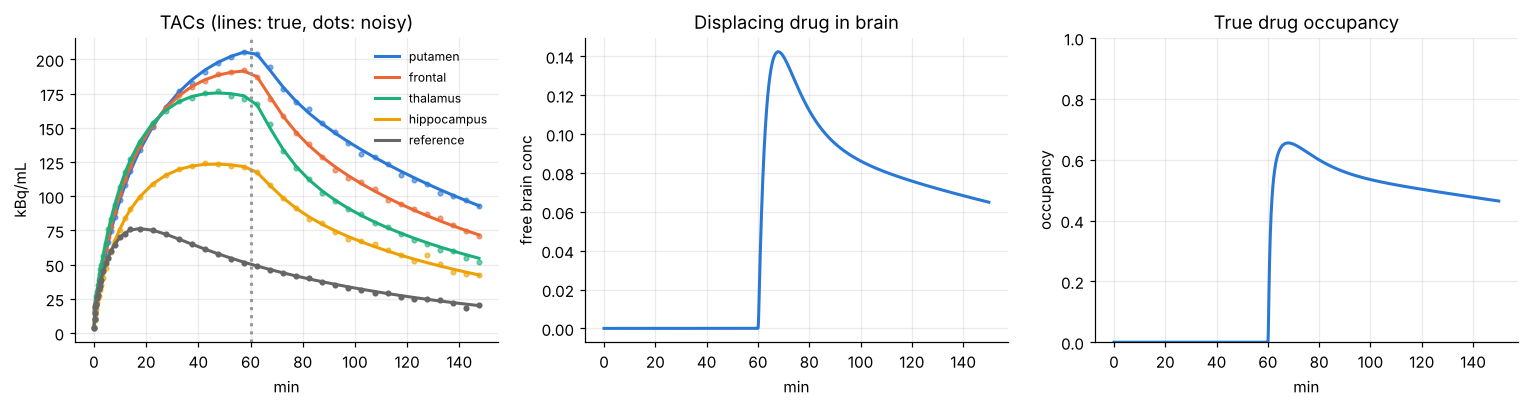

In [3]:
sim = pd.simulate(sc, rng)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
fr = sim.frames
for i, (r, c) in enumerate(zip(sc.regions, [BLUE, ORANGE, AQUA, YELLOW])):
    ax[0].plot(fr.mid, sim.tac_true[i], color=c, label=r.name)
    ax[0].plot(fr.mid, sim.tac[i], "o", ms=3, color=c, alpha=0.6)
ax[0].plot(fr.mid, sim.ref, "o", ms=3, color="0.4"); ax[0].plot(fr.mid, sim.ref_true, color="0.4", label="reference")
ax[0].axvline(sc.drug.t_inj, color="0.6", ls=":"); ax[0].set(xlabel="min", ylabel="kBq/mL", title="TACs (lines: true, dots: noisy)")
ax[0].legend(fontsize=8, frameon=False)
ax[1].plot(sim.t, sim.drug_conc, color=BLUE); ax[1].set(xlabel="min", ylabel="free brain conc", title="Displacing drug in brain")
ax[2].plot(sim.t, sim.occ_t[0], color=BLUE); ax[2].set(xlabel="min", ylabel="occupancy", ylim=(0, 1), title="True drug occupancy")
plt.tight_layout(); print(sim.truth)

## 3. Fit the single scan

* **Drug-driven time-varying SRTM**: BPND(t) = BP0 · (1 − occ(t)), occ(t) = C(t) / (C(t) + EC50).
  Fits R1, k2, BP0 and EC50. Peak occupancy follows from EC50 and the known C(t).
* **Beta-growth time-varying SRTM** (the paper's occupancy function, reference-tissue version): fits occ_max and t_e
  without using the drug's PK. It assumes no drug wash-out during the scan.
* **Standard SRTM** on the pre-drug frames only (baseline BP0).

The endogenous competitor follows from either EC50 with the drug's in-vitro Ki (Cheng-Prusoff:
E/K_E = EC50/Ki − 1), or from BP0 with known Bmax, Kd and fND (E/K_E = fND·Bmax/(Kd·BP0) − 1).

In [4]:
lam = sc.tracer.lam
drug_occ = pd.DrugDrivenOccupancy(conc_fn=sc.drug.conc_fn(), ec50_0=0.2)
beta_occ = pd.BetaGrowthOccupancy(t_b=sc.drug.t_inj, te0=70, te_max=150)

f_drug = pd.fit_tv_srtm(fr, sim.tac[0], sim.ref, drug_occ, lam)
f_beta = pd.fit_tv_srtm(fr, sim.tac[0], sim.ref, beta_occ, lam)
f_pre = pd.fit_srtm(fr, sim.tac[0], sim.ref, lam, t_max=sc.drug.t_inj)
f_multi = pd.fit_tv_srtm_multi(fr, sim.tac, sim.ref, drug_occ, lam)

reg = sc.regions[0]
e1 = pd.endogenous_from_ec50(f_drug.derived["ec50"], sc.drug.ki)
e2 = pd.endogenous_from_bp(f_drug.derived["BP0"], reg.bmax, sc.tracer.kd, sc.tracer.fnd)
print(f"truth:        BP0={sim.truth['bp0'][0]:.3f} occ_peak={sim.occ_t[0].max():.3f} EC50={sc.ec50_app:.4f} E/K_E={sc.endo_ratio}")
print(f"drug tv-SRTM: BP0={f_drug.derived['BP0']:.3f} occ_peak={f_drug.derived['occ_peak']:.3f} EC50={f_drug.derived['ec50']:.4f}"
      f"  E/K_E from EC50={float(e1['endo_ratio']):.3f}, from BP0={float(e2['endo_ratio']):.3f}")
print(f"multi-region: BP0={f_multi.derived['BP0'][0]:.3f} occ_peak={f_multi.derived['occ_peak']:.3f} EC50={f_multi.derived['ec50']:.4f}")
print(f"beta tv-SRTM: BP0={f_beta.derived['BP0']:.3f} occ_max={f_beta.derived['occ_max']:.3f} t_e={f_beta.derived['t_e']:.1f}")
print(f"SRTM pre-drug: BP0={f_pre.derived['BP0']:.3f}")
print("SE (drug tv-SRTM):", {k: round(float(v), 4) for k, v in f_drug.se().items()})

truth:        BP0=4.600 occ_peak=0.655 EC50=0.0750 E/K_E=0.5
drug tv-SRTM: BP0=4.631 occ_peak=0.662 EC50=0.0726  E/K_E from EC50=0.453, from BP0=0.490
multi-region: BP0=4.555 occ_peak=0.654 EC50=0.0751
beta tv-SRTM: BP0=4.546 occ_max=0.580 t_e=60.4
SRTM pre-drug: BP0=4.528
SE (drug tv-SRTM): {'R1': 0.0064, 'k2': 0.001, 'BP0': 0.11, 'log10_ec50': 0.0252}


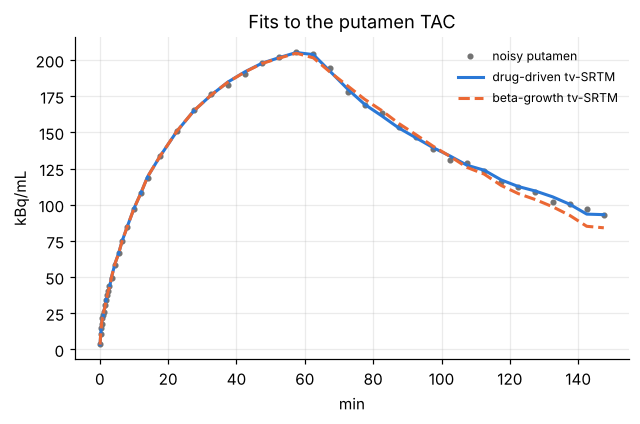

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(fr.mid, sim.tac[0], "o", ms=3, color="0.45", label="noisy putamen")
ax.plot(fr.mid, f_drug.fitted, color=BLUE, label="drug-driven tv-SRTM")
ax.plot(fr.mid, f_beta.fitted, color=ORANGE, ls="--", label="beta-growth tv-SRTM")
ax.set(xlabel="min", ylabel="kBq/mL", title="Fits to the putamen TAC"); ax.legend(frameon=False, fontsize=8)

## 4. The paper's plasma-input model and the Lassen plot

`fit_tv_1tc` is the Laurell et al. multi-region model: shared VND and occupancy parameters, regional K1, BP0, vB.
`StepOccupancy` is the paper's single-step approximation (t_s estimated). For comparison, `simulate_two_scan`
makes a baseline scan and a block scan at a constant brain concentration, analysed with 1TCM and a Lassen plot.

1TC beta: VND=3.83 occ_peak=0.577 BP0=[4.84 3.68 2.73 1.62]
1TC step: VND=3.83 occ_peak=0.577 BP0=[4.84 3.68 2.73 1.62]
1TC drug: VND=3.93 occ_peak=0.654 BP0=[4.72 3.58 2.65 1.55]
Lassen: occ=0.649 (true 0.655), VND=3.87


[Text(0.5, 0, 'VT baseline'),
 Text(0, 0.5, 'VT baseline − VT block'),
 Text(0.5, 1.0, 'Lassen plot')]

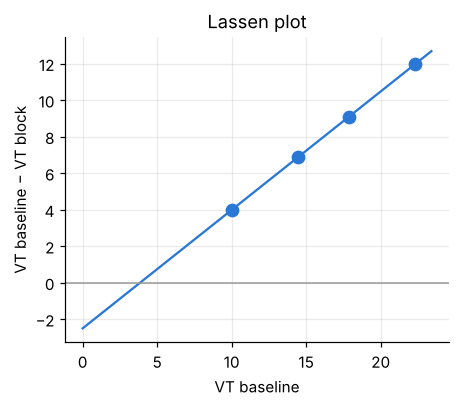

In [6]:
f_1tc_beta = pd.fit_tv_1tc(fr, sim.tac, sim.t, sim.cp, beta_occ, lam)
f_1tc_step = pd.fit_tv_1tc(fr, sim.tac, sim.t, sim.cp, pd.StepOccupancy(t_s0=62, t_s_bounds=(55, 100)), lam)
f_1tc_drug = pd.fit_tv_1tc(fr, sim.tac, sim.t, sim.cp, drug_occ, lam)
for name, f in [("beta", f_1tc_beta), ("step", f_1tc_step), ("drug", f_1tc_drug)]:
    print(f"1TC {name:4s}: VND={f.derived['VND']:.2f} occ_peak={f.derived['occ_peak']:.3f} BP0={np.round(f.derived['BP0'], 2)}")

block_conc = float(sim.drug_conc.max())
base, block, true_occ = pd.simulate_two_scan(sc, block_conc, rng)
vt_b = [pd.fit_1tcm(base.frames, y, base.t, base.cp, lam).derived["VT"] for y in base.tac]
vt_k = [pd.fit_1tcm(block.frames, y, block.t, block.cp, lam).derived["VT"] for y in block.tac]
L = pd.lassen(vt_b, vt_k)
print(f"Lassen: occ={L['occ']:.3f} (true {true_occ:.3f}), VND={L['VND']:.2f}")
fig, ax = plt.subplots(figsize=(4.5, 3.6))
x = np.array(vt_b); ax.plot(x, x - np.array(vt_k), "o", color=BLUE, ms=8)
xx = np.linspace(0, x.max() * 1.05, 10); ax.plot(xx, L["occ"] * xx + L["intercept"], color=BLUE, lw=1.5)
ax.axhline(0, color="0.6", lw=1); ax.set(xlabel="VT baseline", ylabel="VT baseline − VT block", title="Lassen plot")

## 5. Which dose and injection time give the most reliable estimates?

`fisher_design_map` predicts the precision of each estimate from the noise model and the Fisher information of
the drug-driven tv-SRTM, for every (injection time, dose) pair. It runs in well under a second per point.
The trade-offs:

* **Injection time**: later injection leaves more pre-drug frames, so BP0 improves; too late leaves too little
  post-drug data for EC50/occupancy.
* **Dose**: EC50 (and so the endogenous ratio) is best determined when peak occupancy is roughly 60–90%;
  very low occupancy gives almost no displacement signal, and very high occupancy saturates.

best (combined score): {'t_inj': 80.0, 'dose': 22.637390492987745, 'occ_peak': 0.8111623906951155, 'score': 4.156892417588748}


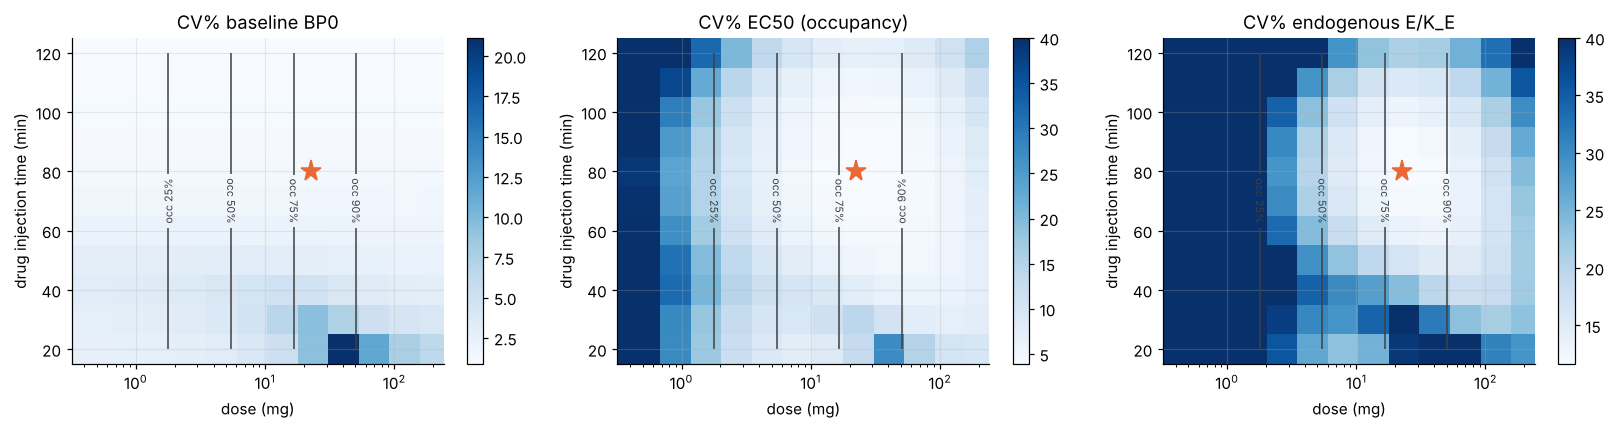

In [7]:
t_grid = np.arange(20, 121, 10)
d_grid = np.geomspace(0.5, 200, 12)
m = pd.fisher_design_map(sc, t_grid, d_grid, regions=(0,))
print("best (combined score):", m["best"])

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for a, key, title in zip(axs, ["cv_bp0", "cv_ec50", "cv_endo_ratio"],
                         ["CV% baseline BP0", "CV% EC50 (occupancy)", "CV% endogenous E/K_E"]):
    im = a.pcolormesh(d_grid, t_grid, np.clip(m[key], 0, 40), cmap="Blues", shading="nearest")
    a.set_xscale("log"); a.set(xlabel="dose (mg)", ylabel="drug injection time (min)", title=title)
    cs = a.contour(d_grid, t_grid, m["occ_peak"], levels=[0.25, 0.5, 0.75, 0.9], colors="0.25", linewidths=1)
    a.clabel(cs, fmt=lambda v: f"occ {v:.0%}", fontsize=7)
    a.plot(m["best"]["dose"], m["best"]["t_inj"], "*", color=ORANGE, ms=14)
    plt.colorbar(im, ax=a)
plt.tight_layout()

Using all regions jointly (shared EC50 and reference efflux) improves precision further. The same call with
`regions=(0, 1, 2, 3)` gives the multi-region map; the BP0 map refers to the first region.

In [8]:
m4 = pd.fisher_design_map(sc, t_grid, d_grid, regions=(0, 1, 2, 3))
print("best multi-region design:", m4["best"])
i = list(t_grid).index(60)
print("CV% EC50 at t_inj=60, by dose (1 region vs 4):")
for d, a, b in zip(d_grid, m["cv_ec50"][i], m4["cv_ec50"][i]):
    print(f"  dose {d:7.2f}  {a:6.2f}  {b:6.2f}")

best multi-region design: {'t_inj': 80.0, 'dose': 22.637390492987745, 'occ_peak': 0.8111623906951155, 'score': 2.2848226800535736}
CV% EC50 at t_inj=60, by dose (1 region vs 4):
  dose    0.50   43.69   18.16
  dose    0.86   26.75   11.16
  dose    1.49   16.94    7.11
  dose    2.56   11.27    4.77
  dose    4.42    7.99    3.43
  dose    7.62    6.12    2.69
  dose   13.13    5.06    2.30
  dose   22.64    4.51    2.16
  dose   39.03    4.36    2.24
  dose   67.29    4.66    2.57
  dose  116.01    5.56    3.26
  dose  200.00    7.35    4.51


### Monte Carlo check

The Fisher map ignores noise in the reference region, parameter bounds and model mismatch. `evaluate_design`
simulates and fits many noisy scans. Here: 40 replicates at a few candidate designs. The beta-growth model
assumes occupancy reaches a plateau; when the drug washes out it underestimates peak occupancy, which the
drug-driven model avoids.

In [9]:
designs = [(40, 10), (60, 3), (60, 10), (60, 30), (m["best"]["t_inj"], m["best"]["dose"]), (100, 30)]
results = [pd.evaluate_design(sc, ti, d, n_rep=40, methods=("drug_srtm", "beta_srtm", "srtm_pre"), seed=7)
           for ti, d in designs]
rows = pd.design_table(results)
try:
    import pandas
    df = pandas.DataFrame(rows)
    show = df[df.quantity.isin(["BP0", "occ_peak", "ec50", "endo_ratio_from_ec50"])]
    display(show.pivot_table(index=["t_inj", "dose", "true_occ_peak"], columns=["method", "quantity"],
                             values="rmse_pct").round(1))
except ImportError:
    for r in rows:
        print(r)

method                       beta_srtm          drug_srtm        \
quantity                           BP0 occ_peak       BP0  ec50   
t_inj dose     true_occ_peak                                      
40.0  10.00000 0.654881           15.3      6.8       7.1  13.8   
60.0  3.00000  0.362759            3.9     24.7       3.5  13.7   
      10.00000 0.654881            4.5     13.6       3.5   7.4   
      30.00000 0.850582            4.9      5.8       3.5   5.9   
80.0  22.63739 0.811162            2.7      5.8       2.5   5.7   
100.0 30.00000 0.850582            2.1      3.6       2.0   6.1   

method                                                     srtm_pre  
quantity                     endo_ratio_from_ec50 occ_peak      BP0  
t_inj dose     true_occ_peak                                         
40.0  10.00000 0.654881                      41.3      4.7      9.2  
60.0  3.00000  0.362759                      41.0      8.1      3.5  
      10.00000 0.654881                      22.1      2.5      3.5  
      30.00000 0.850582                      17.7      0.9      3.5  
80.0  22.63739 0.811162                      17.1      1.1      2.7  
100.0 30.00000 0.850582                      18.3      0.9      2.1

## 6. Fast versus slow drugs

The paper found that estimates improve with faster-acting drugs. Here the brain equilibration rate `keq` is
reduced tenfold (brain half-life of equilibration about 23 min instead of 2.3 min).

fast drug best: {'t_inj': 80.0, 'dose': 22.637390492987745, 'occ_peak': 0.8111623906951155, 'score': 4.156892417588748}
slow drug best: {'t_inj': 80.0, 'dose': 39.02808756829234, 'occ_peak': 0.7985150018640296, 'score': 4.21472844388463}


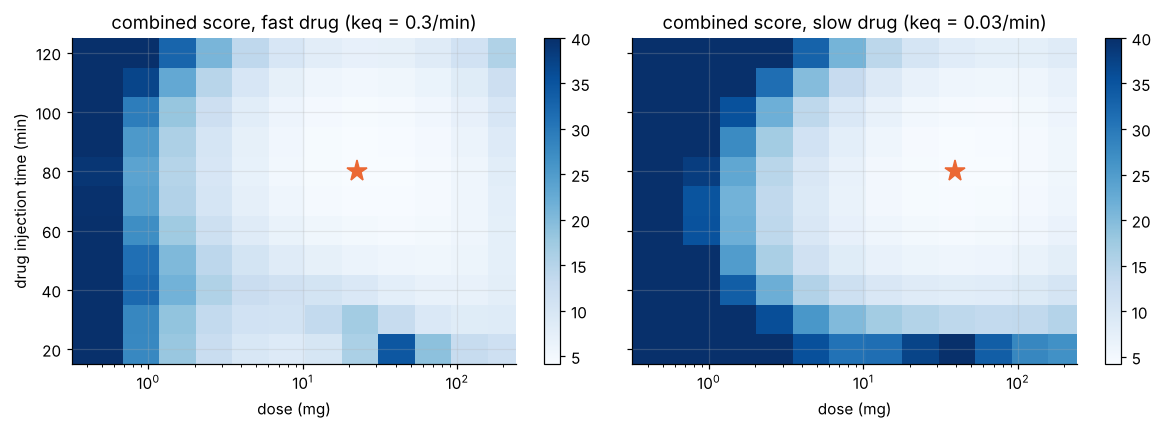

In [10]:
from dataclasses import replace
slow = replace(sc, drug=replace(sc.drug, pk=replace(sc.drug.pk, keq=0.03)))
ms = pd.fisher_design_map(slow, t_grid, d_grid)
print("fast drug best:", m["best"])
print("slow drug best:", ms["best"])
fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, mm, title in zip(axs, [m, ms], ["fast drug (keq = 0.3/min)", "slow drug (keq = 0.03/min)"]):
    im = a.pcolormesh(d_grid, t_grid, np.clip(mm["score"], 0, 40), cmap="Blues", shading="nearest")
    a.set_xscale("log"); a.set(xlabel="dose (mg)", title=f"combined score, {title}")
    a.plot(mm["best"]["dose"], mm["best"]["t_inj"], "*", color=ORANGE, ms=14); plt.colorbar(im, ax=a)
axs[0].set_ylabel("drug injection time (min)"); plt.tight_layout()

## Notes and caveats

* Occupancy here is relative to the baseline *available* receptors (those not already taken by the endogenous
  competitor), which is what a displacement or Lassen analysis measures.
* The endogenous level is identifiable from one scan only through outside knowledge: the drug's in-vitro Ki
  (via EC50) or Bmax, Kd and fND (via BP0). Absolute concentration needs K_E as well.
* SRTM ignores blood volume; with vB = 5% expect about −1.5% bias in BP0 for this tracer.
* The Fisher map assumes a noise-free reference region and correct model; confirm candidate designs with
  `evaluate_design`.
* Set `sc.tracer.molar_activity` (GBq/µmol) to include the tracer's own mass effect, using its Kd.